Exploratory Data Analysis (EDA)

 Predictive Maintenance System

In this phase, we will:

1. Analyze machine failure distribution.
2. Analyze machine types.
3. Visualize numerical features.
4. Compare failed and non-failed machines.
5. Analyze relationships between features.
6. Study machine failure modes.
7. Identify useful patterns for machine failure prediction.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('../data/ai4i2020.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.shape[0]

10000

In [4]:
df.shape[1]

14

In [5]:
df['Machine failure'].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

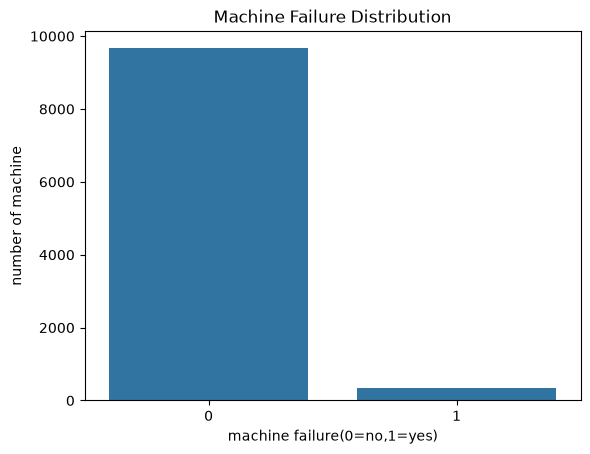

In [6]:
# Visualize Machine Failure Distribution

sns.countplot(data=df,x='Machine failure')
plt.title("Machine Failure Distribution")
plt.xlabel("machine failure(0=no,1=yes)")
plt.ylabel("number of machine")
plt.show()

In [7]:
# Calculate Failure Percentages

failure_percentages=(df['Machine failure'].value_counts(normalize=True)*100)
print(failure_percentages)


Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


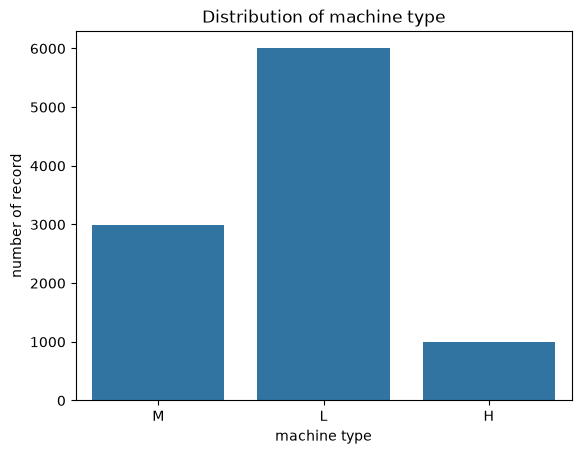

In [8]:
# Visualize Machine Types

sns.countplot(data=df,x='Type')
plt.title("Distribution of machine type")
plt.xlabel("machine type")
plt.ylabel("number of record")
plt.show()




In [9]:
# Analyze Numerical Features

numerical_columns=[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
print(numerical_columns)

['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


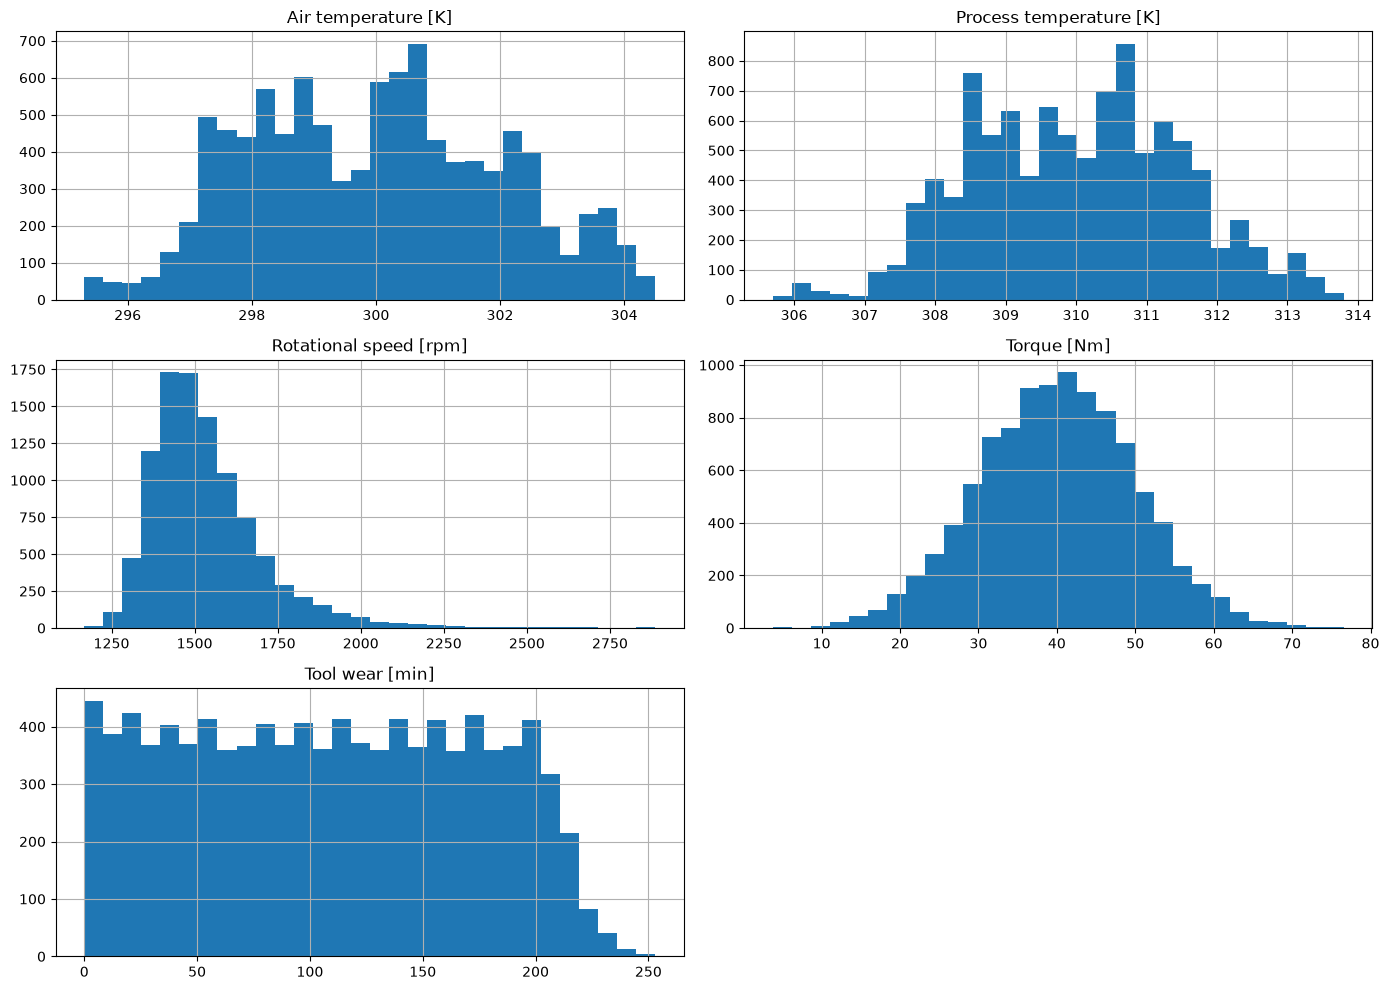

In [10]:
# Plot Feature Distributions

df[numerical_columns].hist(figsize=(14,10),bins=30)
plt.title(" Distributions of machine feature")
plt.tight_layout()
plt.show()

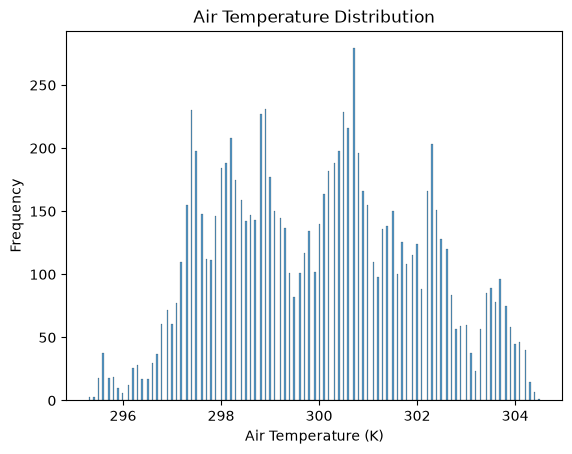

In [11]:
# Analyze Air Temperature

sns.histplot(data=df,x='Air temperature [K]',bins=300)
plt.title("Air Temperature Distribution")
plt.xlabel("Air Temperature (K)")
plt.ylabel("Frequency")
plt.show()



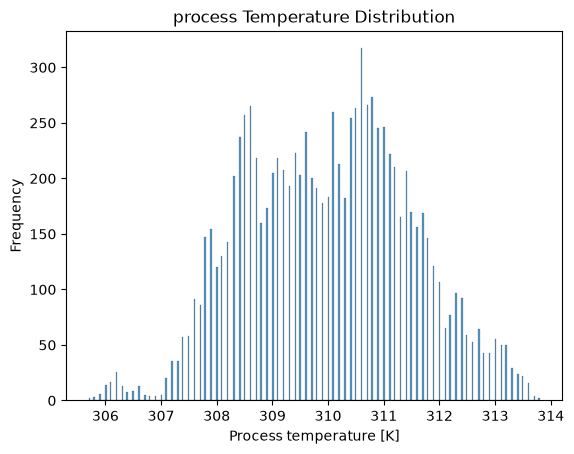

In [12]:
# Analyze Process Temperature

sns.histplot(data=df,x='Process temperature [K]',bins=300)
plt.title("process Temperature Distribution")
plt.xlabel("Process temperature [K]")
plt.ylabel("Frequency")
plt.show()

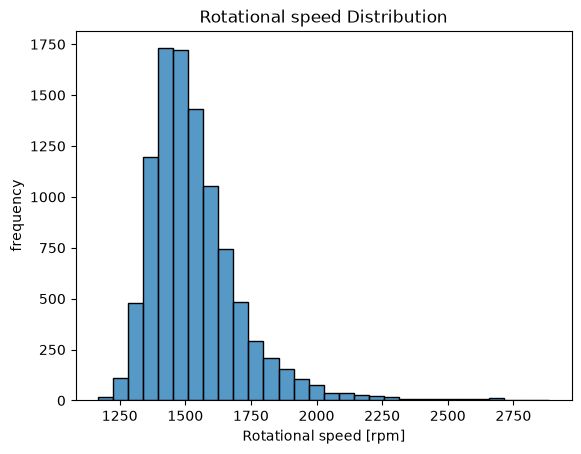

In [13]:
# Analyze Rotational Speed

sns.histplot(data=df,x='Rotational speed [rpm]',bins=30)
plt.title("Rotational speed Distribution")
plt.xlabel("Rotational speed [rpm]")
plt.ylabel("frequency")
plt.show()

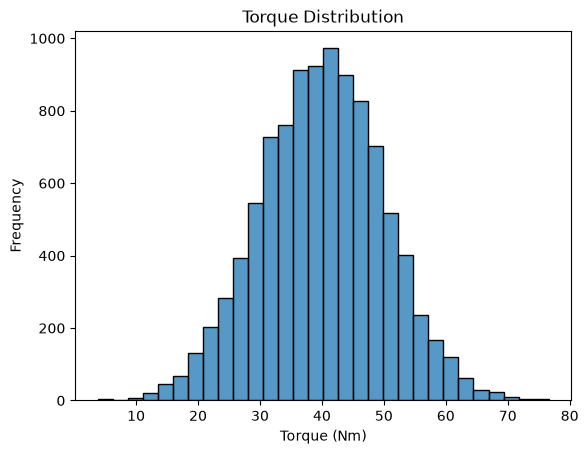

In [14]:
# Analyze Torque
sns.histplot(data=df, x="Torque [Nm]", bins=30)

plt.title("Torque Distribution")
plt.xlabel("Torque (Nm)")
plt.ylabel("Frequency")
plt.show()

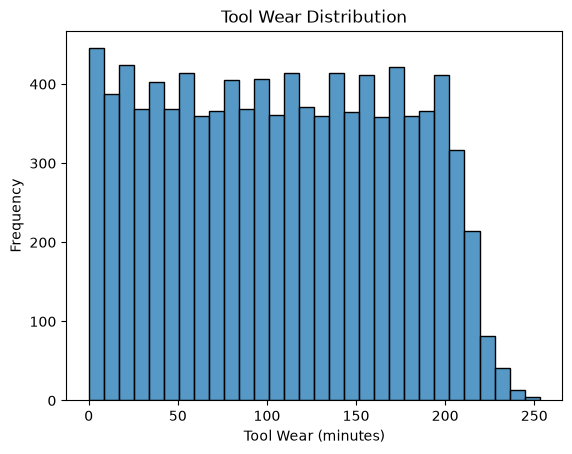

In [15]:
# Analyze Tool Wear

sns.histplot(data=df, x="Tool wear [min]", bins=30)

plt.title("Tool Wear Distribution")
plt.xlabel("Tool Wear (minutes)")
plt.ylabel("Frequency")
plt.show()

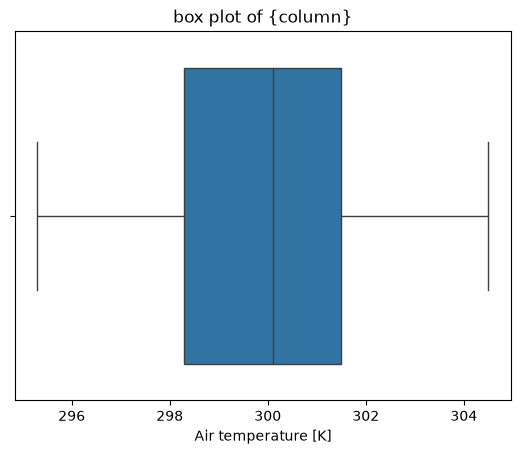

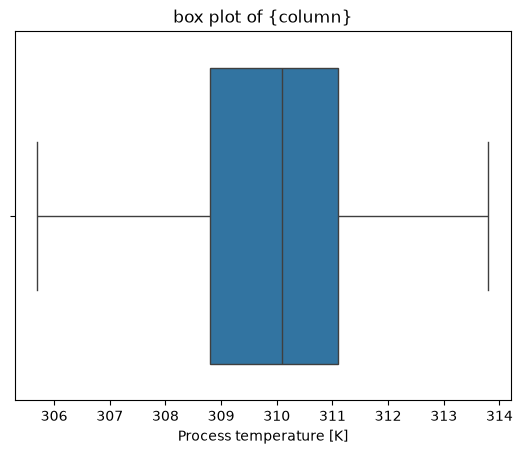

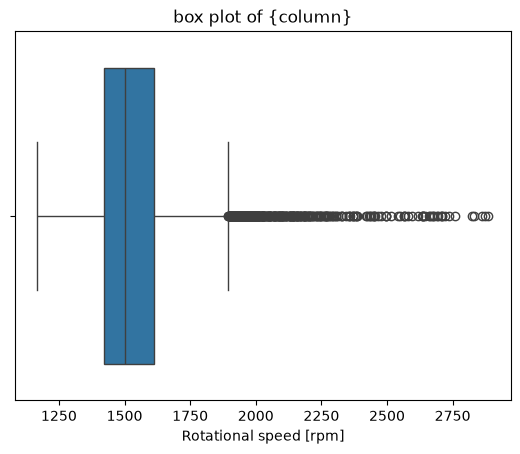

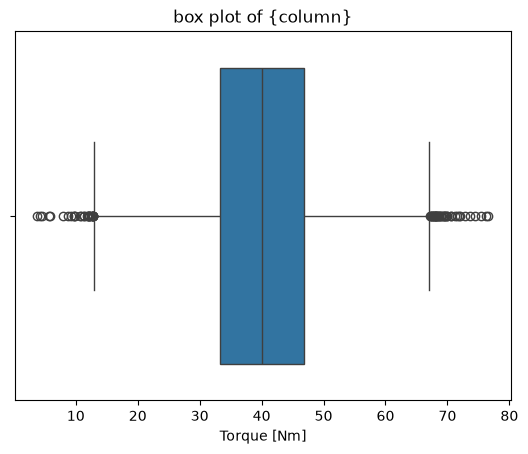

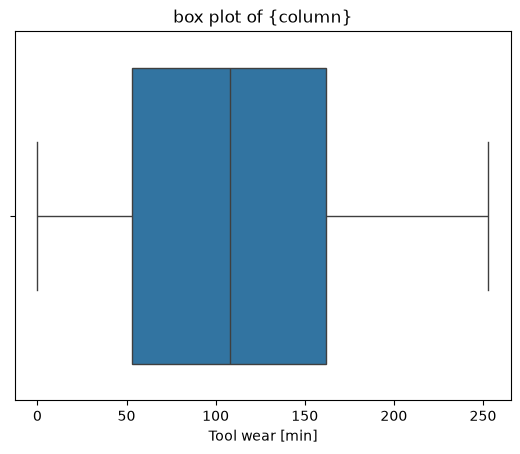

In [16]:
# Compare Features Using Boxplots
# Boxplots help identify potential outliers and compare distributions.

for column in numerical_columns:
    plt.Figure(figsize=(7,4))
    sns.boxplot(data=df,x=column)
    plt.title("box plot of {column}")
    plt.show()

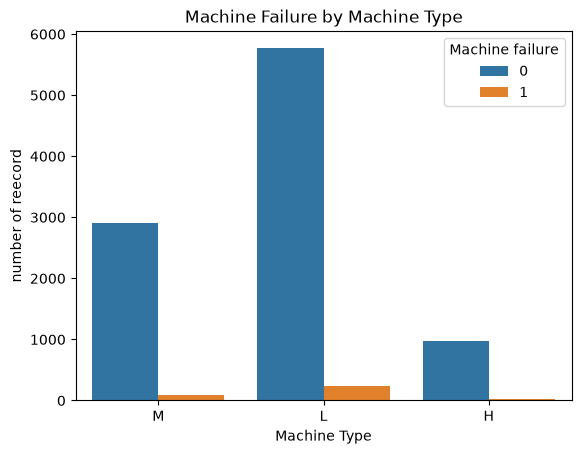

In [17]:
# Compare Machine Types With Failure

sns.countplot(data=df,x='Type',hue='Machine failure')
plt.title("Machine Failure by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("number of reecord")
plt.show()

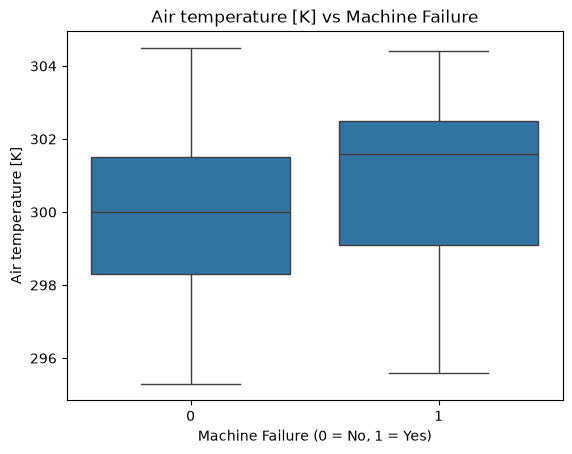

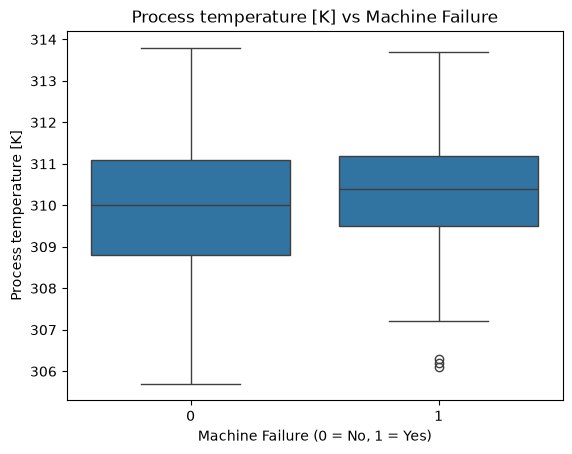

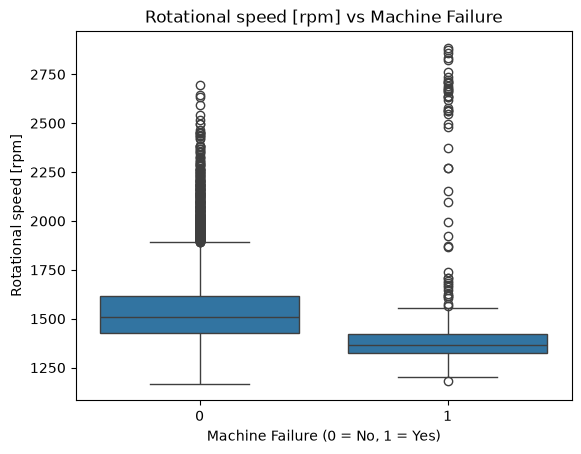

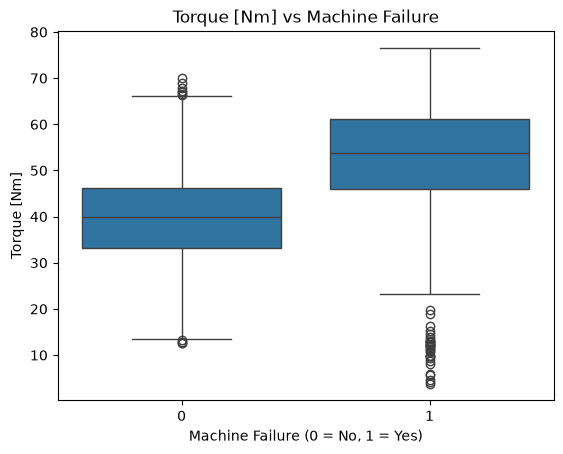

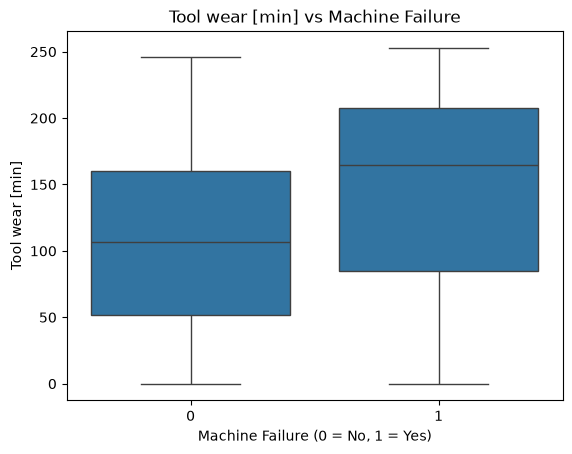

In [20]:
for column in numerical_columns:
    plt.Figure(figsize=(7,4))
    sns.boxplot(data=df,x='Machine failure',y=column)
    plt.title(f"{column} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.ylabel(column)
    plt.show()

In [24]:
# Analyze Correlations Between Main Features
correlation_columns = numerical_columns+['Machine failure']
correlation_matrix = df[correlation_columns].corr()
correlation_matrix



,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


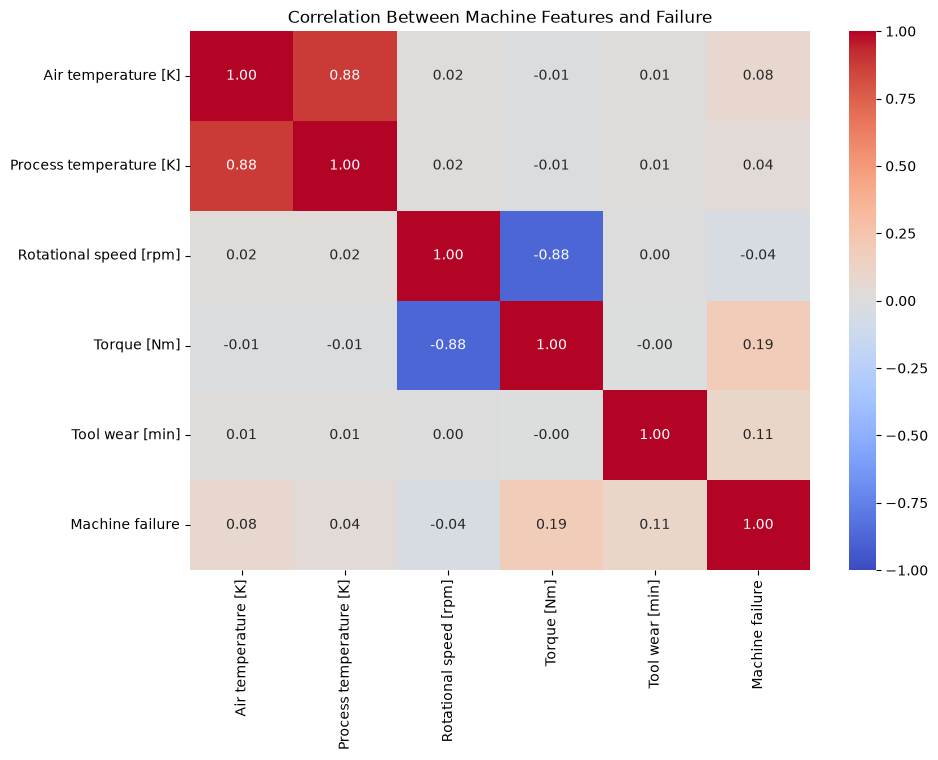

In [25]:
# Visualize the Correlation Matrix

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Machine Features and Failure")
plt.show()

Values near +1 indicate a strong positive linear relationship.



Values near -1 indicate a strong negative linear relationship.



Values near 0 indicate a weak linear relationship.

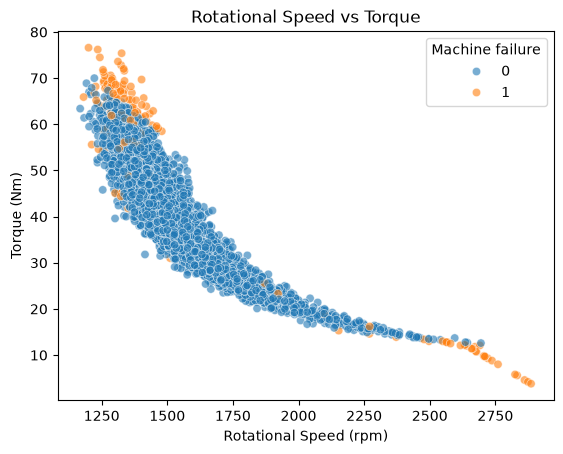

In [27]:
# Analyze Rotational Speed and Torque

sns.scatterplot(data=df,x='Rotational speed [rpm]',y='Torque [Nm]',hue='Machine failure',alpha=0.6)

plt.title("Rotational Speed vs Torque")
plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.show()

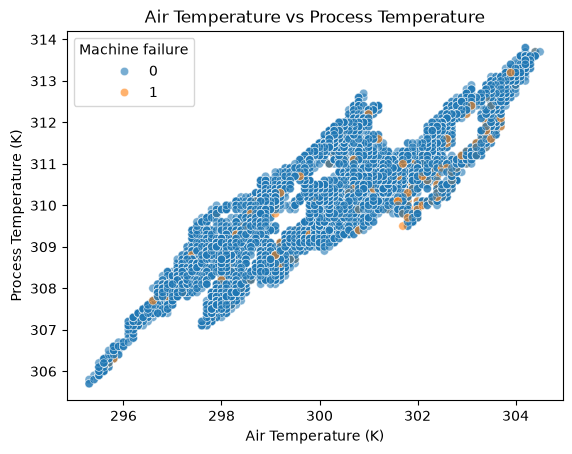

In [29]:
# Analyze Air and Process Temperature

sns.scatterplot(data=df,x='Air temperature [K]',y="Process temperature [K]",hue="Machine failure",alpha=0.6)
plt.title("Air Temperature vs Process Temperature")
plt.xlabel("Air Temperature (K)")
plt.ylabel("Process Temperature (K)")
plt.show()

The dataset includes five failure-mode indicator columns:
- TWF — Tool Wear Failure
- HDF — Heat Dissipation Failure
- PWF — Power Failure
- OSF — Overstrain Failure
- RNF — Random Failure

In [30]:
# Analyze Failure Modes
failure_mode = ["TWF", "HDF", "PWF", "OSF", "RNF"]

for column in failure_mode:
    print(f"\n{column}")
    print(df[column].value_counts())


TWF
TWF
0    9954
1      46
Name: count, dtype: int64

HDF
HDF
0    9885
1     115
Name: count, dtype: int64

PWF
PWF
0    9905
1      95
Name: count, dtype: int64

OSF
OSF
0    9902
1      98
Name: count, dtype: int64

RNF
RNF
0    9981
1      19
Name: count, dtype: int64


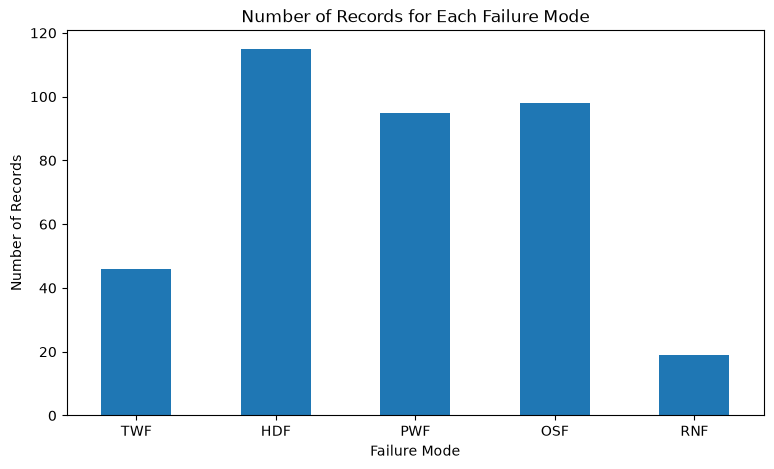

In [31]:
# Visualize Failure Modes

failure_mode_counts = df[failure_mode].sum()

failure_mode_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Number of Records for Each Failure Mode")
plt.xlabel("Failure Mode")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [34]:
feature_comparison = df.groupby("Machine failure")[
    numerical_columns
].mean()

feature_comparison.index = [
    "No Failure",
    "Failure"
]

feature_comparison

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
No Failure,299.973999,309.995570,1540.260014,39.629655,106.693717
Failure,300.886431,310.290265,1496.486726,50.168142,143.781711


In [35]:
print("========== EDA SUMMARY ==========")

print("Dataset Shape:", df.shape)

print("\nMachine Failure Counts:")
print(df["Machine failure"].value_counts())

print("\nMachine Failure Percentages:")
print(
    (df["Machine failure"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMachine Type Counts:")
print(df["Type"].value_counts())

print("\nAverage Feature Values by Machine Failure:")
print(feature_comparison.round(2))

print("\nFailure Mode Counts:")
print(failure_mode_counts)

========== EDA SUMMARY ==========
Dataset Shape: (10000, 14)

Machine Failure Counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine Failure Percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Machine Type Counts:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Average Feature Values by Machine Failure:
            Air temperature [K]  Process temperature [K]  \
No Failure               299.97                   310.00   
Failure                  300.89                   310.29   

            Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
No Failure                 1540.26        39.63           106.69  
Failure                    1496.49        50.17           143.78  

Failure Mode Counts:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


In [28]:
df.head(1)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
